# Training a Mini-GPT on Wine Reviews

## Project
Implement a small autoregressive model from scratch in PyTorch. It predicts the next token, trains on wine review text, and generates new descriptions. We will practice input-target pairs, cross-entropy, a training loop, perplexity, and sampling. The small dataset demonstrates the mechanics, not production-level quality.

## Theoretical Framework: An Autoregressive Language Model as a Distribution Estimator

### A text distribution and its factorization
An unknown corpus can be described by a distribution $p_{data}(x_1,\ldots,x_T)$. The probability chain rule gives the exact factorization:

$$p_\theta(x_1,\ldots,x_T)=\prod_{t=1}^{T}p_\theta(x_t\mid x_1,\ldots,x_{t-1}).$$

GPT parameterizes each conditional distribution with a decoder-only network. Given a prefix, the final position returns logits $z_t\in\mathbb R^V$, and softmax defines $p_\theta(x_t=i\mid x_{<t})=\exp(z_{t,i})/\sum_j\exp(z_{t,j})$. Sampling successive tokens from these distributions gives a procedure for generating a sequence.

### Maximum likelihood and cross-entropy
Maximum-likelihood training maximizes $\sum_t\log p_\theta(x_t\mid x_{<t})$. Equivalently, we minimize the negative log-likelihood, or cross-entropy, of the true tokens. For a batch with padding:

$$\mathcal L(\theta)=-\frac{\sum_{b,t}m_{bt}\log p_\theta(y_{bt}\mid x_{b,\le t})}{\sum_{b,t}m_{bt}},$$

where $m_{bt}=1$ for a real target token and 0 for padding. PyTorch's `ignore_index` excludes padded positions from the loss. Averaging over padding would change the loss scale depending on batch lengths.

Teacher forcing shifts tokens by one position: the input contains $[BOS,x_1,\ldots,x_{T-1}]$, and the target contains $[x_1,\ldots,x_T]$. A causal mask ensures that the logit at position t depends only on inputs up to t. All positions can be computed in parallel during training, although generation remains sequential.

### Perplexity, generalization, and generation
Perplexity is $PPL=\exp(\mathcal L)$ when natural logarithms are used. Intuitively, it is the geometric mean of the inverse probabilities assigned to tokens; it is 1 for a perfectly certain and correct distribution. PPL depends on the tokenizer and corpus, so meaningful comparisons require identical evaluation conventions.

A lower training loss does not prove generalization. A gap between training and validation loss may indicate overfitting, but validation on a small corpus has high variance. Randomly splitting short reviews can also leak similar phrases across splits. A reliable evaluation requires controlling duplicates, defining the split, and keeping a test set that is not used to choose hyperparameters.

During generation, we modify the sampling distribution, not the trained model. Temperature $\tau$ gives $p_i\propto\exp(z_i/\tau)$: as $\tau\to0$, sampling approaches argmax; a higher temperature increases entropy. Top-k truncates the tail to the k highest logits. Top-p selects the smallest set of tokens whose cumulative probability is at least p. These settings change diversity and the risk of implausible continuations, but do not add knowledge or improve the training data.

### What this project demonstrates—and what it does not
The corpus is intentionally small and hand-constructed so the exercise does not require downloading a dataset or obtaining an API key. It lets us inspect gradient flow, shifted targets, padding, causal attention, and generation. It cannot estimate the quality of a model trained on the actual Wine Reviews dataset. A full project needs a real data split, a subword tokenizer, checkpoints, baselines, multiple random seeds, and both metrics and qualitative examples.

## 1. Data and Tokenization
The corpus is offline and educational; replace the list with the description column from a local Wine Reviews CSV. Keep separate train, validation, and test sets, and filter missing values. Word-level tokenization is simplified; practical models use subword tokenization such as BPE.

In [1]:
import math,re,random,torch
from torch import nn
import torch.nn.functional as F
torch.manual_seed(17);random.seed(17);device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
reviews=["aromatic cherry and plum with a long finish","bright acidity balances ripe citrus fruit","dry wine with notes of pear and mineral","soft tannins frame dark berry and spice","fresh apple aroma with crisp acidity","rich oak vanilla and blackcurrant flavors","light bodied wine with floral notes","ripe peach and honey with a smooth finish","structured tannins and earthy cherry notes","zesty lemon aroma and clean mineral finish","bold dark fruit with pepper and toasted oak","delicate strawberry notes and lively acidity","crisp white wine shows lime and green apple","deep ruby color with plum and cocoa","silky texture and a lingering herbal finish","balanced acidity with red cherry aroma","lemon zest meets saline mineral character","blackberry jam with firm structured tannins","fresh floral bouquet and subtle pear flavor","warm spice and vanilla soften ripe plum","elegant wine with bright fruit and fine acidity","earthy notes complement concentrated dark fruit","peach blossom and citrus lead to a clean finish","medium bodied red with cherry and cedar"]
def tok(s):return re.findall(r"[a-z]+|[^\w\s]",s.lower())
special=["<pad>","<unk>","<bos>","<eos>"];vocab=special+sorted({t for s in reviews for t in tok(s)});stoi={t:i for i,t in enumerate(vocab)};PAD=0
seq=[torch.tensor([2]+[stoi.get(t,1) for t in tok(s)]+[3]) for s in reviews]
random.shuffle(seq);cut=int(.8*len(seq));train,val=seq[:cut],seq[cut:]
def collate(rows):
    n=max(map(len,rows));x=torch.full((len(rows),n-1),PAD,dtype=torch.long);y=x.clone()
    for i,s in enumerate(rows):x[i,:len(s)-1]=s[:-1];y[i,:len(s)-1]=s[1:]
    return x.to(device),y.to(device)
x,y=collate(train[:4]);print("train",len(train),"val",len(val),"vocabulary",len(vocab),"x/y",x.shape,y.shape)

train 19 val 5 vocabulary 91 x/y torch.Size([4, 10]) torch.Size([4, 10])


## 2. Next-Token Prediction Objective
We split a sequence $[x_0,\ldots,x_T]$ into input $[x_0,\ldots,x_{T-1}]$ and target $[x_1,\ldots,x_T]$. We minimize $-\sum_t\log p(x_{t+1}\mid x_{\le t})$. Padding is ignored using `ignore_index`.

In [2]:
class CausalAttention(nn.Module):
    def __init__(self,d,h,drop):
        super().__init__();assert d%h==0;self.h=h;self.dh=d//h;self.qkv=nn.Linear(d,3*d);self.proj=nn.Linear(d,d);self.drop=nn.Dropout(drop)
    def forward(self,x):
        B,T,C=x.shape;q,k,v=self.qkv(x).chunk(3,-1)
        def s(z):return z.view(B,T,self.h,self.dh).transpose(1,2)
        q,k,v=map(s,(q,k,v));score=q@k.transpose(-2,-1)/math.sqrt(self.dh)
        mask=torch.tril(torch.ones(T,T,dtype=torch.bool,device=x.device));score=score.masked_fill(~mask,torch.finfo(score.dtype).min)
        return self.drop(self.proj((score.softmax(-1)@v).transpose(1,2).contiguous().view(B,T,C)))
class Block(nn.Module):
    def __init__(self,d,h,drop):
        super().__init__();self.n1=nn.LayerNorm(d);self.a=CausalAttention(d,h,drop);self.n2=nn.LayerNorm(d);self.ff=nn.Sequential(nn.Linear(d,4*d),nn.GELU(),nn.Linear(4*d,d),nn.Dropout(drop))
    def forward(self,x):x=x+self.a(self.n1(x));return x+self.ff(self.n2(x))
class MiniGPT(nn.Module):
    def __init__(self,V,maxlen,d=64,h=4,layers=2,drop=.1):
        super().__init__();self.maxlen=maxlen;self.tok=nn.Embedding(V,d);self.pos=nn.Embedding(maxlen,d);self.blocks=nn.ModuleList([Block(d,h,drop) for _ in range(layers)]);self.ln=nn.LayerNorm(d);self.head=nn.Linear(d,V)
    def forward(self,idx):
        idx=idx[:,-self.maxlen:];T=idx.size(1);p=torch.arange(T,device=idx.device);z=self.tok(idx)+self.pos(p)[None]
        for b in self.blocks:z=b(z)
        return self.head(self.ln(z))
maxlen=max(len(s) for s in seq)-1;model=MiniGPT(len(vocab),maxlen).to(device)
print("parameters",sum(p.numel() for p in model.parameters()),"logity",model(x).shape)

parameters 112475 logity torch.Size([4, 10, 91])


## 3. Training, Cross-Entropy, and Perplexity
Perplexity $\exp(L)$ is the exponential of the mean token-level negative log-likelihood. Lower is better when using the same tokenizer and dataset; do not compare different tokenizers directly.

0 train=4.677 val=4.795 PPL=120.85
20 train=1.653 val=4.330 PPL=75.96
40 train=0.710 val=4.994 PPL=147.48
60 train=0.474 val=5.489 PPL=242.07
80 train=0.426 val=5.755 PPL=315.77
100 train=0.402 val=5.970 PPL=391.57
120 train=0.402 val=6.032 PPL=416.69
140 train=0.385 val=6.085 PPL=439.39
160 train=0.354 val=6.238 PPL=511.64
180 train=0.386 val=6.272 PPL=529.74
200 train=0.378 val=6.376 PPL=587.32


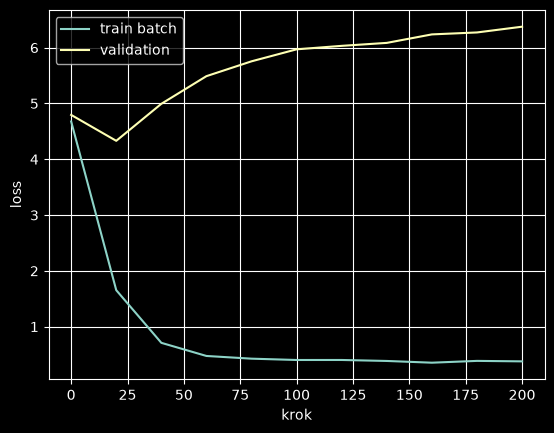

In [3]:
@torch.no_grad()
def evaluate(data):
    model.eval();ls=[]
    for i in range(0,len(data),8):
        a,b=collate(data[i:i+8]);ls.append(F.cross_entropy(model(a).reshape(-1,len(vocab)),b.reshape(-1),ignore_index=PAD).item())
    model.train();return sum(ls)/len(ls)
opt=torch.optim.AdamW(model.parameters(),lr=3e-3,weight_decay=.01);tr=[];va=[]
for step in range(201):
    a,b=collate(random.sample(train,min(8,len(train))));logits=model(a)
    loss=F.cross_entropy(logits.reshape(-1,len(vocab)),b.reshape(-1),ignore_index=PAD)
    opt.zero_grad(set_to_none=True);loss.backward();nn.utils.clip_grad_norm_(model.parameters(),1.);opt.step()
    if step%20==0:
        vl=evaluate(val);tr.append(loss.item());va.append(vl);print(step,f"train={loss.item():.3f} val={vl:.3f} PPL={math.exp(vl):.2f}")
import matplotlib.pyplot as plt
plt.plot(range(0,201,20),tr,label="train batch");plt.plot(range(0,201,20),va,label="validation");plt.xlabel("krok");plt.ylabel("loss");plt.legend();plt.grid();plt.show()

## 4. Generation
We generate iteratively from $p(x_t\mid x_{<t})$. Temperature $\tau$ divides logits by $\tau$: a low temperature concentrates the distribution, while a high temperature flattens it. Top-k removes all but the k highest-logit tokens.

In [4]:
@torch.no_grad()
def generate(prompt="bright acidity",steps=18,temperature=.8,top_k=8):
    model.eval();ids=[2]+[stoi.get(t,1) for t in tok(prompt)];idx=torch.tensor(ids,device=device)[None]
    for _ in range(steps):
        logits=model(idx)[:,-1,:]/max(temperature,1e-5);logits[:,PAD]=-float("inf")
        if top_k:
            threshold=torch.topk(logits,min(top_k,logits.size(-1))).values[:,-1,None];logits=logits.masked_fill(logits<threshold,-float("inf"))
        nxt=torch.multinomial(logits.softmax(-1),1);idx=torch.cat([idx,nxt],1)
        if nxt.item()==3:break
    return " ".join(vocab[i] for i in idx[0].tolist() if vocab[i] not in special)
for t in (.4,.8,1.2):print(f"T={t}:",generate(temperature=t))

T=0.4: bright acidity balances ripe citrus fruit
T=0.8: bright acidity balances ripe citrus fruit
T=1.2: bright acidity balances ripe citrus fruit


## 5. Analysis and Extensions
A small corpus encourages memorization. Validation can reveal a train/validation gap, but the result is unstable with so few examples.

1. Save the checkpoint with the best validation loss and add early stopping.
2. Implement nucleus sampling (top-p).
3. Replace the tokenizer with a subword tokenizer and compare sequence lengths and PPL.
4. Load a local Wine Reviews CSV, filter missing values, and reserve a test set.
5. Record generations, decoding settings, and examples of errors.

## Summary
Teacher forcing computes loss over all prefixes in parallel, while the causal mask prevents information leakage. Cross-entropy is the training objective; PPL is its exponential transform. Sampling controls diversity, but cannot fix poor data or model limitations.

## Key Takeaways

- An autoregressive language model factorizes a sequence probability as $p(x_{1:T})=\prod_t p(x_t\mid x_{<t})$.
- Teacher forcing shifts input and target by one token, allowing all next-token losses to be computed in parallel under a causal mask.
- Cross-entropy is the negative log-likelihood objective; padding positions must be excluded from the loss.
- Perplexity is $\exp(\mathcal L)$ and is only directly comparable under the same tokenizer and evaluation setup.
- Temperature, top-k, and top-p change the sampling distribution at inference; they do not improve the learned model or add knowledge.
- A tiny educational corpus demonstrates mechanics but cannot support reliable claims about real-world language-model quality.